In [2]:
%pip install numpy pandas matplotlib scikit-learn


[notice] A new release of pip available: 22.3.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import re
import unicodedata

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score
)

RANDOM_STATE = 42
N_STATES = 5

np.random.seed(RANDOM_STATE)

In [4]:
DATA_DIR = Path("../Data")
RESULTS_DIR = Path("results")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Data folder exists:", DATA_DIR.exists())

if not DATA_DIR.exists():
    raise FileNotFoundError("Cannot find ../Data")

print("\nFeature files:", len(list(DATA_DIR.glob("*_features.csv"))))
print("Processed files:", len(list(DATA_DIR.glob("*_processed.csv"))))

Working directory: /Users/sara/Desktop/Senior Project/FES-Exoskeleton-Project/Data Analysis 1 - Sara
Data folder exists: True

Feature files: 26
Processed files: 26


In [5]:
MOVEMENTS = {
    "abduct": "abduction",
    "elevate": "elevating",
    "flex": "flexing",
    "sitting": "sitting",
    "standing": "standing",
    "walking": "walking"
}

def clean_filename(filename):
    filename = unicodedata.normalize("NFKC", filename)

    filename = "".join(
        char for char in filename
        if unicodedata.category(char) != "Cf"
    )

    return filename.strip().lower()

def recording_key(filepath):
    name = clean_filename(filepath.stem)

    name = re.sub(
        r"_(features|processed)$",
        "",
        name
    )

    movement = None

    for prefix, label in MOVEMENTS.items():
        if name.startswith(prefix):
            movement = label
            break

    if movement is None:
        return None

    match = re.search(r"z\s*(\d+)", name)

    if match:
        trial = int(match.group(1))
    elif movement == "standing":
        trial = 1
    else:
        return None

    return movement, trial

In [6]:
import pandas as pd
import re
import unicodedata

# Store all loaded recordings
all_recordings = []

# Find all feature CSV files inside Data
csv_files = sorted(DATA_DIR.glob("*_features.csv"))

# Loop through every CSV file
for filepath in csv_files:

    # Get the filename without the extension
    filename = filepath.stem

    # Normalize Unicode characters
    filename = unicodedata.normalize("NFKC", filename)

    # Remove invisible formatting characters
    filename = "".join(
        char for char in filename
        if unicodedata.category(char) != "Cf"
    )

    # Remove extra spaces and convert to lowercase
    filename_lower = filename.strip().lower()

    # Identify the movement
    if filename_lower.startswith("abduct"):
        movement = "abduction"

    elif filename_lower.startswith("elevate"):
        movement = "elevating"

    elif filename_lower.startswith("flex"):
        movement = "flexing"

    elif filename_lower.startswith("sitting"):
        movement = "sitting"

    elif filename_lower.startswith("standing"):
        movement = "standing"

    elif filename_lower.startswith("walking"):
        movement = "walking"

    else:
        print(f"Unknown movement: {filepath.name}")
        continue

    # Extract the recording number
    match = re.search(r"z\s*(\d+)", filename_lower)

    if match:
        trial = int(match.group(1))

    elif movement == "standing":
        trial = 1

    else:
        print(f"Missing trial number: {filepath.name}")
        continue

    # Read the feature CSV
    df = pd.read_csv(filepath)

    # Add movement label
    df["label"] = movement

    # Add trial number
    df["trial"] = trial

    # Add unique recording ID
    df["recording_id"] = f"{movement}_z{trial}"

    # Store the recording
    all_recordings.append(df)

# Check that recordings were found
if not all_recordings:
    raise FileNotFoundError(
        "No EMG feature files found in Data."
    )

# Combine all recordings
data = pd.concat(
    all_recordings,
    ignore_index=True
)

# Display results
print("Dataset loaded successfully!")

print("\nDataset shape:")
print(data.shape)

print("\nNumber of windows per movement:")
print(data["label"].value_counts())

print("\nNumber of recordings per movement:")
print(
    data.groupby("label")["recording_id"].nunique()
)

print("\nTotal recordings loaded:")
print(data["recording_id"].nunique())

Dataset loaded successfully!

Dataset shape:
(2281, 55)

Number of windows per movement:
label
flexing      654
elevating    520
abduction    342
walking      326
sitting      277
standing     162
Name: count, dtype: int64

Number of recordings per movement:
label
abduction    5
elevating    5
flexing      5
sitting      5
standing     1
walking      5
Name: recording_id, dtype: int64

Total recordings loaded:
26


In [7]:
from pathlib import Path
import re
import unicodedata

DATA_DIR = Path("../Data")

def clean_name(filename):
    # Normalize Unicode characters
    filename = unicodedata.normalize("NFKC", filename)

    # Remove invisible formatting characters
    filename = "".join(
        char for char in filename
        if unicodedata.category(char) != "Cf"
    )

    # Convert to lowercase and remove surrounding spaces
    return filename.strip().lower()


def get_recording_key(filepath):

    name = clean_name(filepath.stem)

    # Remove the file-type suffix
    name = re.sub(
        r"_(features|processed)$",
        "",
        name
    )

    # Identify movement
    if name.startswith("abduct"):
        movement = "abduction"

    elif name.startswith("elevate"):
        movement = "elevating"

    elif name.startswith("flex"):
        movement = "flexing"

    elif name.startswith("sitting"):
        movement = "sitting"

    elif name.startswith("standing"):
        movement = "standing"

    elif name.startswith("walking"):
        movement = "walking"

    else:
        return None

    # Extract trial number
    match = re.search(r"z\s*(\d+)", name)

    if match:
        trial = int(match.group(1))

    elif movement == "standing":
        trial = 1

    else:
        return None

    return movement, trial


feature_files = {}
processed_files = {}

# Find feature files
for filepath in DATA_DIR.glob("*_features.csv"):
    key = get_recording_key(filepath)

    if key is not None:
        if key in feature_files:
            raise ValueError(f"Duplicate feature file: {key}")

        feature_files[key] = filepath

# Find processed files
for filepath in DATA_DIR.glob("*_processed.csv"):
    key = get_recording_key(filepath)

    if key is not None:
        if key in processed_files:
            raise ValueError(f"Duplicate processed file: {key}")

        processed_files[key] = filepath

# Find recordings with both file types
common_keys = sorted(
    set(feature_files) & set(processed_files)
)

print("Feature recordings:", len(feature_files))
print("Processed recordings:", len(processed_files))
print("Matched recordings:", len(common_keys))

print("\nMissing processed files:")

for key in sorted(set(feature_files) - set(processed_files)):
    print(key)

print("\nMissing feature files:")

for key in sorted(set(processed_files) - set(feature_files)):
    print(key)

Feature recordings: 26
Processed recordings: 26
Matched recordings: 26

Missing processed files:

Missing feature files:


In [8]:
if not common_keys:
    raise ValueError("No matching feature and processed files found.")

example_key = common_keys[0]

example_features = pd.read_csv(
    feature_files[example_key]
)

example_processed = pd.read_csv(
    processed_files[example_key]
)

print("Example recording:", example_key)

print("\nFeature columns:")
print(example_features.columns.tolist())

print("\nProcessed columns:")
print(example_processed.columns.tolist())

display(example_processed.head())

Example recording: ('abduction', 1)

Feature columns:
['start_sample_index', 'end_sample_index', 'start_time_s', 'end_time_s', 'label', 'Multifidus_R_rms', 'Multifidus_R_mav', 'Multifidus_R_iemg', 'Multifidus_R_waveform_length', 'Multifidus_R_zero_crossings', 'Multifidus_R_slope_sign_changes', 'Multifidus_L_rms', 'Multifidus_L_mav', 'Multifidus_L_iemg', 'Multifidus_L_waveform_length', 'Multifidus_L_zero_crossings', 'Multifidus_L_slope_sign_changes', 'ExternalOblique_R_rms', 'ExternalOblique_R_mav', 'ExternalOblique_R_iemg', 'ExternalOblique_R_waveform_length', 'ExternalOblique_R_zero_crossings', 'ExternalOblique_R_slope_sign_changes', 'ExternalOblique_L_rms', 'ExternalOblique_L_mav', 'ExternalOblique_L_iemg', 'ExternalOblique_L_waveform_length', 'ExternalOblique_L_zero_crossings', 'ExternalOblique_L_slope_sign_changes', 'RectusAbdominis_R_rms', 'RectusAbdominis_R_mav', 'RectusAbdominis_R_iemg', 'RectusAbdominis_R_waveform_length', 'RectusAbdominis_R_zero_crossings', 'RectusAbdominis_R_

,sample_index,nominal_time_s,Time_s,Multifidus_R_emg,Multifidus_L_emg,ExternalOblique_R_emg,ExternalOblique_L_emg,RectusAbdominis_R_emg,RectusAbdominis_L_emg,ErectorSpinae_R_emg,...,RectusAbdominis_L_emg_rectified,RectusAbdominis_L_emg_envelope,ErectorSpinae_R_emg_centered,ErectorSpinae_R_emg_filtered,ErectorSpinae_R_emg_rectified,ErectorSpinae_R_emg_envelope,ErectorSpinae_L_emg_centered,ErectorSpinae_L_emg_filtered,ErectorSpinae_L_emg_rectified,ErectorSpinae_L_emg_envelope
0,0,0.0000,0.0000,-6.7240,18.2156,45.1001,-104.3664,-11.2937,45.4500,-47.2983,...,1.132221,0.000000,-47.3052,-1.239670,1.239670,0.317937,-19.2272,-0.509586,0.509586,0.385058
1,1,0.0005,0.0005,-5.8085,14.8584,42.3534,-98.5677,-11.2937,43.6189,-43.9411,...,0.920838,0.000000,-43.9480,-0.174216,0.174216,0.413705,-18.6168,-0.779651,0.779651,0.419405
2,2,0.0010,0.0010,-4.8929,10.2805,39.9118,-88.8015,-10.9885,39.3461,-39.3632,...,0.044896,0.057715,-39.3701,1.207663,1.207663,0.509082,-17.3961,-0.947065,0.947065,0.453656
3,3,0.0015,0.0015,-3.0617,8.1442,38.6911,-78.7301,-9.7677,35.3786,-34.7853,...,1.175489,0.117970,-34.7922,3.016211,3.016211,0.604050,-15.8701,-0.914044,0.914044,0.487803
4,4,0.0020,0.0020,-0.3150,10.2805,38.3859,-70.7950,-8.2418,32.3267,-29.9022,...,2.272047,0.177900,-29.9091,5.402386,5.402386,0.698593,-14.3441,-0.287075,0.287075,0.521843


In [9]:
standing_key = ("standing", 1)

if standing_key not in processed_files:
    raise FileNotFoundError(
        "Standing processed file is required."
    )

standing = pd.read_csv(
    processed_files[standing_key]
)

def accel_tilt_deg(df, side):

    x = df[f"Thigh_{side}_Accel_X"].to_numpy(dtype=float)
    y = df[f"Thigh_{side}_Accel_Y"].to_numpy(dtype=float)
    z = df[f"Thigh_{side}_Accel_Z"].to_numpy(dtype=float)

    tilt = np.degrees(
        np.arctan2(
            np.sqrt(x**2 + y**2),
            z
        )
    )

    return tilt


neutral_L = np.nanmedian(
    accel_tilt_deg(standing, "L")
)

neutral_R = np.nanmedian(
    accel_tilt_deg(standing, "R")
)

print(f"Left neutral orientation: {neutral_L:.2f}°")
print(f"Right neutral orientation: {neutral_R:.2f}°")

Left neutral orientation: 101.63°
Right neutral orientation: 101.06°


In [10]:
import numpy as np
import pandas as pd

# Number of movement states
N_STATES = 5


# --------------------------------------------------
# Function 1: Normalize movement scores
# --------------------------------------------------

def normalize_movement_score(values):

    # Create a writable copy of the values
    values = np.array(
        values,
        dtype=float,
        copy=True
    )

    # Replace infinite values with NaN
    values[~np.isfinite(values)] = np.nan

    # Check whether all values are missing
    if np.all(np.isnan(values)):
        return np.full_like(values, np.nan)

    # Calculate the 95th percentile
    high = np.nanpercentile(values, 95)

    # Check whether normalization is possible
    if not np.isfinite(high) or high <= 0:
        return np.full_like(values, np.nan)

    # Normalize movement values
    score = values / high

    # Keep values between 0 and 1
    score = np.clip(score, 0, 1)

    return score


# --------------------------------------------------
# Function 2: Convert movement scores into states
# --------------------------------------------------

def score_to_state(score):

    # Convert scores into a NumPy array
    score = np.array(
        score,
        dtype=float,
        copy=True
    )

    # Create an array for the states
    states = np.full(
        score.shape,
        np.nan
    )

    # Identify valid scores
    valid = np.isfinite(score)

    # Convert valid scores into states S0-S4
    states[valid] = np.clip(
        np.floor(score[valid] * N_STATES),
        0,
        N_STATES - 1
    )

    return states


# --------------------------------------------------
# Function 3: Generate bilateral leg states
# --------------------------------------------------

def generate_states(processed):

    # Copy the processed dataset
    result = processed.copy()

    # Calculate left and right thigh orientations
    tilt_L = accel_tilt_deg(result, "L")
    tilt_R = accel_tilt_deg(result, "R")

    # Calculate movement relative to standing
    result["Movement_L"] = np.abs(
        tilt_L - neutral_L
    )

    result["Movement_R"] = np.abs(
        tilt_R - neutral_R
    )

    # Normalize movement scores
    result["MovementScore_L"] = normalize_movement_score(
        result["Movement_L"]
    )

    result["MovementScore_R"] = normalize_movement_score(
        result["Movement_R"]
    )

    # Convert scores into movement states
    result["State_L"] = score_to_state(
        result["MovementScore_L"]
    )

    result["State_R"] = score_to_state(
        result["MovementScore_R"]
    )

    # Count missing states
    missing_L = result["State_L"].isna().sum()
    missing_R = result["State_R"].isna().sum()

    if missing_L > 0 or missing_R > 0:

        print(
            f"Warning: {missing_L} missing left states, "
            f"{missing_R} missing right states."
        )

    return result


print("Bilateral state generation functions created successfully!")

Bilateral state generation functions created successfully!


In [11]:
# Store all aligned recordings
all_aligned = []

# Count skipped windows
skipped_windows = 0

# Store alignment statistics
alignment_summary = []

# Loop through every matched recording
for key in common_keys:

    movement, trial = key

    # Load EMG feature data
    features = pd.read_csv(
        feature_files[key]
    )

    # Load processed EMG/IMU data
    processed = pd.read_csv(
        processed_files[key]
    )

    # Generate left and right states
    processed = generate_states(processed)

    # Sort processed samples
    processed = processed.sort_values(
        "sample_index"
    )

    # Get sample indices
    sample_indices = processed[
        "sample_index"
    ].to_numpy()

    aligned_rows = []

    recording_skipped = 0

    # Loop through each EMG feature window
    for _, row in features.iterrows():

        # Window start and end indices
        start = int(
            row["start_sample_index"]
        )

        end = int(
            row["end_sample_index"]
        )

        # Find processed samples in this window
        mask = (
            (sample_indices >= start)
            &
            (sample_indices <= end)
        )

        window = processed.loc[mask]

        # Remove samples with invalid states
        window = window.dropna(
            subset=["State_L", "State_R"]
        )

        # Skip windows without valid bilateral states
        if window.empty:

            skipped_windows += 1
            recording_skipped += 1

            continue

        # Most frequent left-leg state
        state_L = int(
            window["State_L"].mode().iloc[0]
        )

        # Most frequent right-leg state
        state_R = int(
            window["State_R"].mode().iloc[0]
        )

        # Copy feature data
        output = row.to_dict()

        # Add state labels
        output["State_L"] = state_L
        output["State_R"] = state_R

        # Add movement information
        output["movement"] = movement

        output["trial"] = trial

        output["recording_id"] = (
            f"{movement}_z{trial}"
        )

        aligned_rows.append(output)

    # Save aligned recording
    if aligned_rows:

        all_aligned.append(
            pd.DataFrame(aligned_rows)
        )

    # Store recording statistics
    alignment_summary.append({
        "Recording": f"{movement}_z{trial}",
        "Original Windows": len(features),
        "Aligned Windows": len(aligned_rows),
        "Skipped Windows": recording_skipped
    })


# Check whether alignment succeeded
if not all_aligned:

    raise ValueError(
        "No valid aligned windows were created."
    )

# Combine aligned recordings
data = pd.concat(
    all_aligned,
    ignore_index=True
)

# Create alignment summary
alignment_summary = pd.DataFrame(
    alignment_summary
)

print("Alignment completed successfully!")

print("\nAligned dataset shape:")
print(data.shape)

print("\nNumber of recordings:")
print(data["recording_id"].nunique())

print("\nTotal skipped windows:")
print(skipped_windows)

print("\nAlignment summary:")
display(alignment_summary)

print("\nFirst 10 aligned windows:")

display(
    data[
        [
            "movement",
            "recording_id",
            "State_L",
            "State_R"
        ]
    ].head(10)
)

Alignment completed successfully!

Aligned dataset shape:
(2281, 58)

Number of recordings:
26

Total skipped windows:
0

Alignment summary:


,Recording,Original Windows,Aligned Windows,Skipped Windows
0,abduction_z1,70,70,0
1,abduction_z2,56,56,0
2,abduction_z3,66,66,0
3,abduction_z4,72,72,0
4,abduction_z5,78,78,0
5,elevating_z1,120,120,0
6,elevating_z2,122,122,0
7,elevating_z3,99,99,0
8,elevating_z4,84,84,0
9,elevating_z5,95,95,0



First 10 aligned windows:


,movement,recording_id,State_L,State_R
0,abduction,abduction_z1,0,0
1,abduction,abduction_z1,0,0
2,abduction,abduction_z1,0,0
3,abduction,abduction_z1,0,0
4,abduction,abduction_z1,0,0
5,abduction,abduction_z1,0,0
6,abduction,abduction_z1,1,0
7,abduction,abduction_z1,0,1
8,abduction,abduction_z1,0,1
9,abduction,abduction_z1,1,1


In [12]:
print("DATA QUALITY CHECK")

print("\nTotal aligned windows:")
print(len(data))

print("\nNumber of recordings:")
print(data["recording_id"].nunique())

print("\nMissing left-leg states:")
print(data["State_L"].isna().sum())

print("\nMissing right-leg states:")
print(data["State_R"].isna().sum())

print("\nRecordings per movement:")

print(
    data.groupby("movement")[
        "recording_id"
    ].nunique()
)

print("\nLeft-leg state distribution:")

print(
    data["State_L"].value_counts().sort_index()
)

print("\nRight-leg state distribution:")

print(
    data["State_R"].value_counts().sort_index()
)

print("\nState ranges:")

print(
    "Left:",
    data["State_L"].min(),
    "to",
    data["State_L"].max()
)

print(
    "Right:",
    data["State_R"].min(),
    "to",
    data["State_R"].max()
)

DATA QUALITY CHECK

Total aligned windows:
2281

Number of recordings:
26

Missing left-leg states:
0

Missing right-leg states:
0

Recordings per movement:
movement
abduction    5
elevating    5
flexing      5
sitting      5
standing     1
walking      5
Name: recording_id, dtype: int64

Left-leg state distribution:
State_L
0    854
1    342
2    368
3    300
4    417
Name: count, dtype: int64

Right-leg state distribution:
State_R
0    1354
1     202
2     114
3     152
4     459
Name: count, dtype: int64

State ranges:
Left: 0 to 4
Right: 0 to 4


In [13]:
# Define EMG feature types
FEATURE_SUFFIXES = (
    "_rms",
    "_mav",
    "_iemg",
    "_waveform_length",
    "_zero_crossings",
    "_slope_sign_changes"
)

# Select EMG feature columns
feature_columns = [
    column
    for column in data.columns
    if column.endswith(FEATURE_SUFFIXES)
]

print("Number of selected features:", len(feature_columns))

# Verify feature count
if len(feature_columns) != 48:

    raise ValueError(
        f"Expected 48 EMG features, "
        f"but found {len(feature_columns)}."
    )

# Convert features to numerical values
data[feature_columns] = data[
    feature_columns
].apply(
    pd.to_numeric,
    errors="coerce"
)

# Replace infinite values with NaN
data[feature_columns] = data[
    feature_columns
].replace(
    [np.inf, -np.inf],
    np.nan
)

print("\nEMG features selected successfully!")

print("\nSelected feature names:")

for feature in feature_columns:
    print(feature)

Number of selected features: 48

EMG features selected successfully!

Selected feature names:
Multifidus_R_rms
Multifidus_R_mav
Multifidus_R_iemg
Multifidus_R_waveform_length
Multifidus_R_zero_crossings
Multifidus_R_slope_sign_changes
Multifidus_L_rms
Multifidus_L_mav
Multifidus_L_iemg
Multifidus_L_waveform_length
Multifidus_L_zero_crossings
Multifidus_L_slope_sign_changes
ExternalOblique_R_rms
ExternalOblique_R_mav
ExternalOblique_R_iemg
ExternalOblique_R_waveform_length
ExternalOblique_R_zero_crossings
ExternalOblique_R_slope_sign_changes
ExternalOblique_L_rms
ExternalOblique_L_mav
ExternalOblique_L_iemg
ExternalOblique_L_waveform_length
ExternalOblique_L_zero_crossings
ExternalOblique_L_slope_sign_changes
RectusAbdominis_R_rms
RectusAbdominis_R_mav
RectusAbdominis_R_iemg
RectusAbdominis_R_waveform_length
RectusAbdominis_R_zero_crossings
RectusAbdominis_R_slope_sign_changes
RectusAbdominis_L_rms
RectusAbdominis_L_mav
RectusAbdominis_L_iemg
RectusAbdominis_L_waveform_length
RectusAbdo

In [14]:
# Exclude standing from initial classification
model_data = data[
    data["movement"] != "standing"
].copy()

# Define recording splits
TRAIN_TRIALS = [1, 2, 3]

VAL_TRIALS = [4]

TEST_TRIALS = [5]

# Create masks
train_mask = model_data["trial"].isin(
    TRAIN_TRIALS
)

val_mask = model_data["trial"].isin(
    VAL_TRIALS
)

test_mask = model_data["trial"].isin(
    TEST_TRIALS
)

# Training features
X_train = model_data.loc[
    train_mask,
    feature_columns
].copy()

# Validation features
X_val = model_data.loc[
    val_mask,
    feature_columns
].copy()

# Testing features
X_test = model_data.loc[
    test_mask,
    feature_columns
].copy()

# Training labels
y_train = model_data.loc[
    train_mask,
    ["State_L", "State_R"]
].copy()

# Validation labels
y_val = model_data.loc[
    val_mask,
    ["State_L", "State_R"]
].copy()

# Testing labels
y_test = model_data.loc[
    test_mask,
    ["State_L", "State_R"]
].copy()

print("Training shape:", X_train.shape)

print("Validation shape:", X_val.shape)

print("Testing shape:", X_test.shape)

Training shape: (1289, 48)
Validation shape: (408, 48)
Testing shape: (422, 48)


In [15]:
# Get recording IDs for each dataset
train_ids = set(
    model_data.loc[
        train_mask,
        "recording_id"
    ]
)

val_ids = set(
    model_data.loc[
        val_mask,
        "recording_id"
    ]
)

test_ids = set(
    model_data.loc[
        test_mask,
        "recording_id"
    ]
)

# Verify no recording appears in multiple datasets
assert train_ids.isdisjoint(val_ids)

assert train_ids.isdisjoint(test_ids)

assert val_ids.isdisjoint(test_ids)

print("Training recordings:", len(train_ids))

print("Validation recordings:", len(val_ids))

print("Testing recordings:", len(test_ids))

print("\nTraining left-leg state distribution:")

print(
    y_train["State_L"].value_counts().sort_index()
)

print("\nTraining right-leg state distribution:")

print(
    y_train["State_R"].value_counts().sort_index()
)

print("\nRecording split verified successfully!")

Training recordings: 15
Validation recordings: 5
Testing recordings: 5

Training left-leg state distribution:
State_L
0    395
1    231
2    238
3    182
4    243
Name: count, dtype: int64

Training right-leg state distribution:
State_R
0    774
1     85
2     56
3    103
4    271
Name: count, dtype: int64

Recording split verified successfully!


In [16]:
from sklearn.dummy import DummyClassifier

from sklearn.multioutput import MultiOutputClassifier

from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score
)

import matplotlib.pyplot as plt
import joblib

In [17]:
baseline_model = Pipeline([

    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),

    (
        "classifier",
        MultiOutputClassifier(
            DummyClassifier(
                strategy="most_frequent"
            )
        )
    )

])

print("Bilateral Baseline model created successfully!")

Bilateral Baseline model created successfully!


In [18]:
baseline_model.fit(
    X_train,
    y_train
)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [19]:
# Generate predictions
baseline_pred = baseline_model.predict(
    X_test
)

# Separate left and right predictions
pred_L = baseline_pred[:, 0]

pred_R = baseline_pred[:, 1]

print("First 10 bilateral predictions:")

for left, right in zip(
    pred_L[:10],
    pred_R[:10]
):

    print(
        f"Left: S{left} | "
        f"Right: S{right} | "
        f"Bilateral: L{left}_R{right}"
    )

First 10 bilateral predictions:
Left: S0 | Right: S0 | Bilateral: L0_R0
Left: S0 | Right: S0 | Bilateral: L0_R0
Left: S0 | Right: S0 | Bilateral: L0_R0
Left: S0 | Right: S0 | Bilateral: L0_R0
Left: S0 | Right: S0 | Bilateral: L0_R0
Left: S0 | Right: S0 | Bilateral: L0_R0
Left: S0 | Right: S0 | Bilateral: L0_R0
Left: S0 | Right: S0 | Bilateral: L0_R0
Left: S0 | Right: S0 | Bilateral: L0_R0
Left: S0 | Right: S0 | Bilateral: L0_R0


In [20]:
# Left-leg accuracy
accuracy_L = accuracy_score(
    y_test["State_L"],
    pred_L
)

# Right-leg accuracy
accuracy_R = accuracy_score(
    y_test["State_R"],
    pred_R
)

# Bilateral exact-match accuracy
bilateral_accuracy = np.mean(
    (
        pred_L == y_test["State_L"].to_numpy()
    )
    &
    (
        pred_R == y_test["State_R"].to_numpy()
    )
)

print("BASELINE CLASSIFIER RESULTS")

print(
    f"Left-leg accuracy: "
    f"{accuracy_L * 100:.2f}%"
)

print(
    f"Right-leg accuracy: "
    f"{accuracy_R * 100:.2f}%"
)

print(
    f"Bilateral accuracy: "
    f"{bilateral_accuracy * 100:.2f}%"
)

BASELINE CLASSIFIER RESULTS
Left-leg accuracy: 46.21%
Right-leg accuracy: 61.37%
Bilateral accuracy: 36.26%


In [21]:
print("LEFT LEG CLASSIFICATION REPORT")

print(
    classification_report(
        y_test["State_L"],
        pred_L,
        labels=range(N_STATES),
        zero_division=0
    )
)

print("\nRIGHT LEG CLASSIFICATION REPORT")

print(
    classification_report(
        y_test["State_R"],
        pred_R,
        labels=range(N_STATES),
        zero_division=0
    )
)

LEFT LEG CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.46      1.00      0.63       195
           1       0.00      0.00      0.00        36
           2       0.00      0.00      0.00        43
           3       0.00      0.00      0.00        64
           4       0.00      0.00      0.00        84

    accuracy                           0.46       422
   macro avg       0.09      0.20      0.13       422
weighted avg       0.21      0.46      0.29       422


RIGHT LEG CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.61      1.00      0.76       259
           1       0.00      0.00      0.00        31
           2       0.00      0.00      0.00        26
           3       0.00      0.00      0.00        23
           4       0.00      0.00      0.00        83

    accuracy                           0.61       422
   macro avg       0.12      0.20      0.15       422
weighted avg 

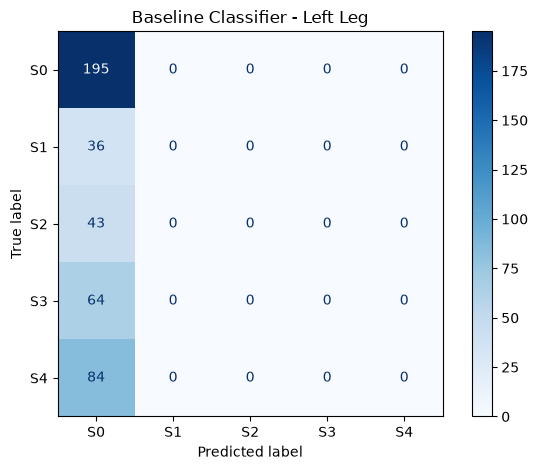

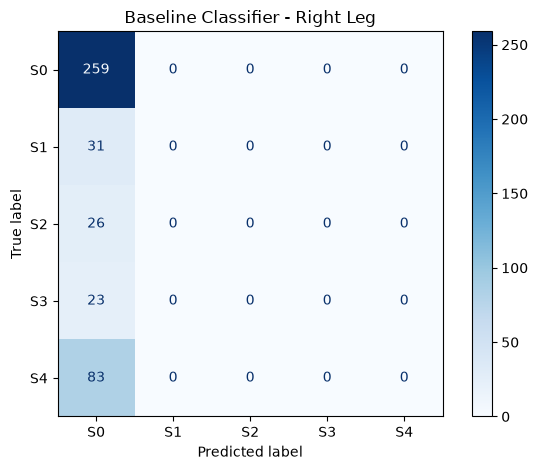

In [22]:
for side, actual, predicted in [

    (
        "Left",
        y_test["State_L"],
        pred_L
    ),

    (
        "Right",
        y_test["State_R"],
        pred_R
    )

]:

    ConfusionMatrixDisplay.from_predictions(
        actual,
        predicted,
        labels=range(N_STATES),
        display_labels=[
            f"S{i}"
            for i in range(N_STATES)
        ],
        cmap="Blues"
    )

    plt.title(
        f"Baseline Classifier - {side} Leg"
    )

    plt.tight_layout()

    plt.show()

In [23]:
# Create a results DataFrame
test_results = pd.DataFrame({

    "Time_s": model_data.loc[
        test_mask,
        "end_time_s"
    ].to_numpy(),

    "recording_id": model_data.loc[
        test_mask,
        "recording_id"
    ].to_numpy(),

    "ActualState_L": y_test[
        "State_L"
    ].to_numpy(),

    "ActualState_R": y_test[
        "State_R"
    ].to_numpy(),

    "CandidateState_L": pred_L,

    "CandidateState_R": pred_R

})

# Create bilateral state label
test_results["BilateralState"] = (

    "L"
    + test_results[
        "CandidateState_L"
    ].astype(str)

    + "_R"

    + test_results[
        "CandidateState_R"
    ].astype(str)

)

print("First 1000 predictions:")

display(
    test_results.head(1000)
)

First 1000 predictions:


,Time_s,recording_id,ActualState_L,ActualState_R,CandidateState_L,CandidateState_R,BilateralState
0,0.1995,abduction_z5,0,0,0,0,L0_R0
1,0.2994,abduction_z5,0,0,0,0,L0_R0
2,0.3994,abduction_z5,0,0,0,0,L0_R0
3,0.4994,abduction_z5,0,0,0,0,L0_R0
4,0.5994,abduction_z5,0,0,0,0,L0_R0
...,...,...,...,...,...,...,...
417,6.1984,walking_z5,2,1,0,0,L0_R0
418,6.2984,walking_z5,2,1,0,0,L0_R0
419,6.3984,walking_z5,2,1,0,0,L0_R0
420,6.4983,walking_z5,2,1,0,0,L0_R0


In [24]:
# Maximum allowed state jump
MAX_STATE_JUMP = 3

# Initialize output columns
test_results["AcceptedState_L"] = 0

test_results["AcceptedState_R"] = 0

test_results["FaultFlag"] = False

# Process each recording separately
for recording_id, group in test_results.groupby(
    "recording_id",
    sort=False
):

    prev_L = None
    prev_R = None

    # Check each prediction
    for index, row in group.iterrows():

        cand_L = int(
            row["CandidateState_L"]
        )

        cand_R = int(
            row["CandidateState_R"]
        )

        # First prediction in a recording
        if prev_L is None:

            prev_L = cand_L
            prev_R = cand_R

            fault = False

        else:

            # Check state jumps
            jump_L = abs(
                cand_L - prev_L
            )

            jump_R = abs(
                cand_R - prev_R
            )

            fault = (
                jump_L > MAX_STATE_JUMP
                or
                jump_R > MAX_STATE_JUMP
            )

            # Accept valid transitions
            if not fault:

                prev_L = cand_L
                prev_R = cand_R

        # Store accepted states
        test_results.loc[
            index,
            "AcceptedState_L"
        ] = prev_L

        test_results.loc[
            index,
            "AcceptedState_R"
        ] = prev_R

        test_results.loc[
            index,
            "FaultFlag"
        ] = fault


print("Transition validation completed!")

print(
    "Detected transition faults:",
    test_results["FaultFlag"].sum()
)

Transition validation completed!
Detected transition faults: 0
